# TAREA 3 · SEMANA 11
# Red neuronal con TensorFlow y Keras

**Reporte de proyecto en Jupyter · 6 horas de referencia**

Estudiante: ____________________  
Curso / docente: ____________________  
Fecha: ____________________

Este cuaderno sustituye el informe e incluye teoría, diagrama de flujo, implementación, resultados ejecutados y conclusiones. Los datos son sintéticos y reproducibles.

## Preparación
Abrir en Jupyter o Google Colab. Ejecutar todas las celdas en orden. Si faltan bibliotecas, instalar requirements.txt o descomentar la siguiente celda.

In [1]:
%matplotlib inline
# %pip install numpy matplotlib scikit-learn scipy tensorflow

## Objetivo y problema
Clasificar puntos de un círculo interior y otro exterior mediante una red neuronal no lineal.

## Fundamento: operaciones de la semana 11
Una red neuronal artificial combina unidades con pesos, sesgos y activaciones. Su importancia en IA consiste en aprender relaciones y representaciones complejas para texto, imagen, audio y datos tabulares.

Su estructura comprende entrada, capas ocultas y salida. La propagación hacia delante calcula predicciones; la pérdida mide error y la retropropagación calcula gradientes que un optimizador usa para modificar pesos. Sin activaciones no lineales, apilar capas densas no crea una frontera no lineal.

Tipos: perceptrón para separación lineal; MLP densa para relaciones no lineales; CNN para estructura espacial; RNN/LSTM para secuencias; Transformers para relaciones mediante atención; autoencoders para representación y reconstrucción.

## Datos y arquitectura
3000 puntos sintéticos con make_circles, factor 0.45 y ruido 0.12. Se comparan dos arquitecturas densas, 16–8 y 24–12, con la misma partición. Se selecciona la menor pérdida en validación y se evalúa una sola vez en prueba. Particiones estratificadas de 60 % entrenamiento, 20 % validación y 20 % prueba. StandardScaler se ajusta solo con entrenamiento. Se construyen MLP de TensorFlow/Keras: 2 entradas → dos capas ocultas ReLU → 1 sigmoide. La versión ampliada dispone de más ejemplos y mayor ruido que el primer experimento; sus cifras no deben compararse directamente con las del conjunto anterior, que era más sencillo. Usa entropía cruzada binaria, Adam y umbral 0.5. EarlyStopping observa validación y restaura los mejores pesos; la prueba no guía el ajuste.


## Diagrama de flujo de la función principal
Se dibuja con Python y queda guardado como PNG, sin servicios externos.

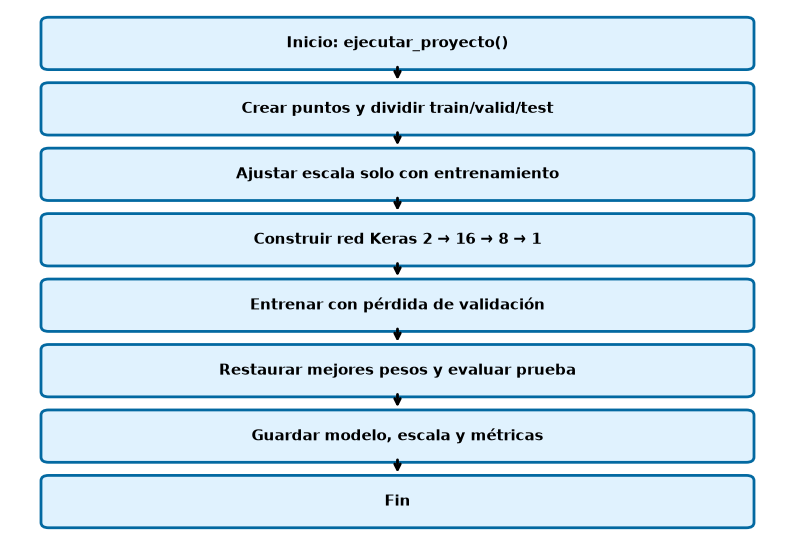

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from matplotlib.patches import FancyBboxPatch
pasos=['Inicio: ejecutar_proyecto()', 'Crear puntos y dividir train/valid/test', 'Ajustar escala solo con entrenamiento', 'Construir red Keras 2 → 16 → 8 → 1', 'Entrenar con pérdida de validación', 'Restaurar mejores pesos y evaluar prueba', 'Guardar modelo, escala y métricas', 'Fin']
fig,ax=plt.subplots(figsize=(10,len(pasos)*.85)); ax.set(xlim=(0,10),ylim=(0,len(pasos)*1.25)); ax.axis('off')
for i,paso in enumerate(pasos):
    y=(len(pasos)-i-1)*1.25+.2
    ax.add_patch(FancyBboxPatch((.5,y),9,.8,boxstyle='round,pad=.1',facecolor='#e0f2fe',edgecolor='#0369a1',linewidth=2))
    ax.text(5,y+.4,paso,ha='center',va='center',fontsize=11,fontweight='bold')
    if i<len(pasos)-1:ax.annotate('',xy=(5,y-.35),xytext=(5,y),arrowprops={'arrowstyle':'->','lw':2})
plt.savefig('resultados/diagrama_flujo.png',dpi=140,bbox_inches='tight'); plt.show()


## Implementación y resultados
Las salidas siguientes proceden de ejecutar este código.

C:\Users\LORENA\OneDrive\Documents\ChatGPT\TAREAS CURSOS\Entregas_semanas_09_12\_entorno_validacion\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Arquitectura: (16, 8) Pérdida validación: 0.020609764382243156 Exactitud validación: 0.9933333333333333


C:\Users\LORENA\OneDrive\Documents\ChatGPT\TAREAS CURSOS\Entregas_semanas_09_12\_entorno_validacion\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Arquitectura: (24, 12) Pérdida validación: 0.020409511402249336 Exactitud validación: 0.99
Arquitectura elegida: (24, 12)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 24)             │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,157 (4.52 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 772 (3.02 KB)

Exactitud de prueba: 0.9966666666666667
Matriz (filas reales, columnas predichas): [[300   0]
 [  2 298]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       300
           1       1.00      0.99      1.00       300

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



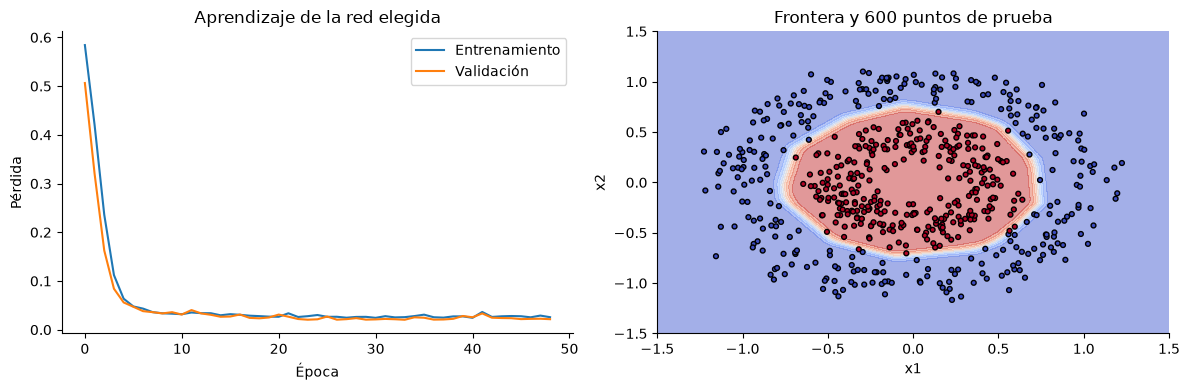

### Interpretación de la ejecución
La red seleccionada obtuvo **99.7%** de aciertos en **600 puntos nuevos**, con capas **(24, 12)**. Se entrenó con **1800** ejemplos y eligió entre dos arquitecturas usando **600** ejemplos de validación. La pérdida de validación elegida fue **0.0204**. Los datos son sintéticos: el resultado no garantiza exactitud en fotografías u otros problemas.

562

In [3]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
import tensorflow as tf
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,log_loss

def ejecutar_proyecto():
    X,y=make_circles(n_samples=3000,factor=.45,noise=.12,random_state=2026)
    np.savetxt('datos.csv',np.c_[X,y],delimiter=',',header='x1,x2,clase',comments='')
    a,t,b,u=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
    a,v,b,w=train_test_split(a,b,test_size=.25,stratify=b,random_state=42)
    scaler=StandardScaler().fit(a)
    options=tf.data.Options(); options.threading.private_threadpool_size=1
    train=tf.data.Dataset.from_tensor_slices((scaler.transform(a).astype('float32'),b.astype('float32'))).shuffle(len(b),seed=42).batch(64).with_options(options)
    valid=tf.data.Dataset.from_tensor_slices((scaler.transform(v).astype('float32'),w.astype('float32'))).batch(64).with_options(options)
    candidates=[]
    for widths in [(16,8),(24,12)]:
        tf.keras.utils.set_random_seed(42)
        model=tf.keras.Sequential([tf.keras.Input(shape=(2,)),tf.keras.layers.Dense(widths[0],activation='relu'),tf.keras.layers.Dense(widths[1],activation='relu'),tf.keras.layers.Dense(1,activation='sigmoid')])
        model.compile(optimizer=tf.keras.optimizers.Adam(.005),loss='binary_crossentropy',metrics=['accuracy'])
        history=model.fit(train,validation_data=valid,epochs=140,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=15,restore_best_weights=True)])
        vp=model(scaler.transform(v).astype('float32'),training=False).numpy().ravel()
        score=float(log_loss(w,vp))
        candidates.append((score,model,history,widths))
        print('Arquitectura:',widths,'Pérdida validación:',score,'Exactitud validación:',accuracy_score(w,vp>=.5))
    score,model,history,widths=min(candidates,key=lambda item:item[0])
    # La prueba se consulta después de elegir arquitectura por validación.
    prob=model(scaler.transform(t).astype('float32'),training=False).numpy().ravel(); pred=(prob>=.5).astype(int)
    acc=float(accuracy_score(u,pred)); cm=confusion_matrix(u,pred)
    print('Arquitectura elegida:',widths); model.summary()
    print('Exactitud de prueba:',acc); print('Matriz (filas reales, columnas predichas):',cm); print(classification_report(u,pred,zero_division=0))
    fig,ax=plt.subplots(1,2,figsize=(12,4)); ax[0].plot(history.history['loss'],label='Entrenamiento'); ax[0].plot(history.history['val_loss'],label='Validación'); ax[0].legend(); ax[0].set(xlabel='Época',ylabel='Pérdida',title='Aprendizaje de la red elegida')
    xx,yy=np.meshgrid(np.linspace(-1.5,1.5,120),np.linspace(-1.5,1.5,120)); zz=model(scaler.transform(np.c_[xx.ravel(),yy.ravel()]).astype('float32'),training=False).numpy().reshape(xx.shape)
    ax[1].contourf(xx,yy,zz,levels=np.linspace(0,1,11),cmap='coolwarm',alpha=.5); ax[1].scatter(t[:,0],t[:,1],c=u,cmap='coolwarm',edgecolors='black',s=12); ax[1].set(xlabel='x1',ylabel='x2',title='Frontera y 600 puntos de prueba')
    plt.tight_layout(); plt.savefig('resultados/proyecto.png',dpi=140); plt.show()
    model.save('resultados/modelo.keras'); np.savez('resultados/escalador.npz',media=scaler.mean_,escala=scaler.scale_)
    validation=[{'capas':list(z[3]),'perdida_validacion':z[0]} for z in candidates]
    resultado={'exactitud':acc,'matriz_confusion':cm.tolist(),'epocas':len(history.history['loss']),'parametros':model.count_params(),'entrenamiento':len(b),'validacion':len(w),'prueba':len(u),'capas':[2,*widths,1],'comparacion':validation,'ruido':.12,'semilla_datos':2026}
    web={'pesos':[z.tolist() for z in model.get_weights()],'media':scaler.mean_.tolist(),'escala':scaler.scale_.tolist(),'evaluacion':resultado}
    Path('resultados/red_web.json').write_text(json.dumps(web),encoding='utf-8')
    display(Markdown(f"### Interpretación de la ejecución\nLa red seleccionada obtuvo **{acc:.1%}** de aciertos en **{len(u)} puntos nuevos**, con capas **{widths}**. Se entrenó con **{len(b)}** ejemplos y eligió entre dos arquitecturas usando **{len(w)}** ejemplos de validación. La pérdida de validación elegida fue **{score:.4f}**. Los datos son sintéticos: el resultado no garantiza exactitud en fotografías u otros problemas."))
    return resultado

metricas=ejecutar_proyecto()
Path('resultados/metricas.json').write_text(json.dumps(metricas,indent=2),encoding='utf-8')


## Conclusiones, limitaciones y exploración
La MLP aprende una frontera no lineal gracias a ReLU. Validación y prueba cumplen funciones distintas y previenen una evaluación optimista. La semilla mejora reproducibilidad, aunque hardware y versiones pueden variar resultados. El desempeño se limita a puntos sintéticos. Explorar: usar activación lineal en capas ocultas o aumentar el ruido; comparar frontera y matriz de confusión. La mejora se comprueba comparando arquitecturas sobre la misma validación. Más neuronas o más épocas no aseguran mayor exactitud. Cambiar deslizadores consulta el modelo; no reentrena ni recopila datos de usuarios.

## Referencias oficiales
- https://www.tensorflow.org/tutorials/quickstart/beginner
- https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping